# Running demo

This notebook runs the simulations of the paper. Each selected simulation is run once: it simulates the data, matches the cells, and shows the matching plots and metrics.

**To run it:** choose **Run > Run All Cells**. As set, it runs only S1, in seconds.

It doesn't change anything in `results/`. To see the saved results of 10 repeats, open `evaluation_demo.ipynb`.


In [1]:
import sys
sys.path.insert(0, "..")  # lets the notebook find the code in this repository

%matplotlib inline
import time

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from gmixomix import graph_matching_withD
from results.metrics import calc_stats
from results.plots import plot_latent_space, plot_matching
from simulations import configs, data, run


## 1. Choose the simulations

List the ones you want in `SIMS`, for example `["S2", "S7"]`. To run all 11, use the second line instead, which takes about 40 minutes.

Rough time for one simulation on 6 threads: S1 seconds, S2 under a minute, S3 to S10 about 2 minutes, S11 about 25 minutes.


In [2]:
#SIMS = ["S1"]
SIMS = list(configs.PAPER_SIMULATIONS)  # all 11

for label, name in configs.PAPER_SIMULATIONS.items():
    print(f"{label:>3}  {configs.SIMULATIONS[name]['description']}")


 S1  Identical latent space, adjacency only
 S2  Latent space with tiny noise, adjacency only
 S3  Latent space with more noise, adjacency only
 S4  Same noise as 3 with more neighbours
 S5  Latent adjacency helped by noiseless RNA and ATAC
 S6  Latent adjacency helped by noisy RNA and ATAC
 S7  Graphs from noisy RNA and ATAC, latent space not accessible
 S8  As 7, RNA generated with a different D (5% of rows zeroed)
 S9  As 8, with 70% of rows zeroed
S10  As 8', with stronger regularization (c3=2000)
S11  As 9, with RNA and ATAC converted to Poisson counts


## 2. Run them

Each line in a plot connects a cell in one dataset to its match in the other. Colours show the true clusters, so a good matching mostly connects cells of the same colour.


### S1: Identical latent space, adjacency only

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


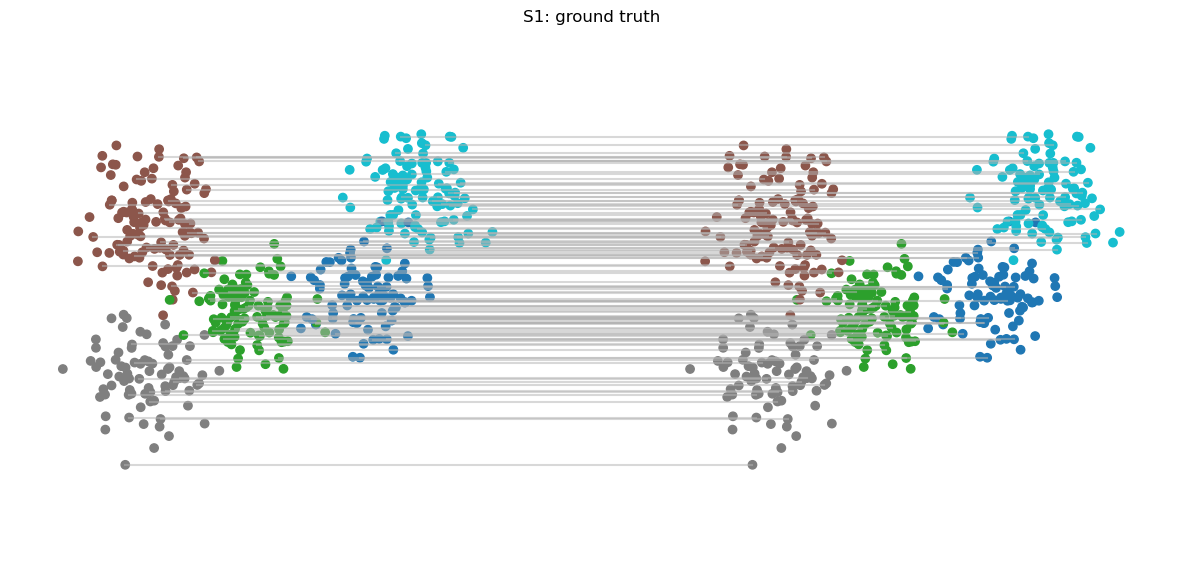

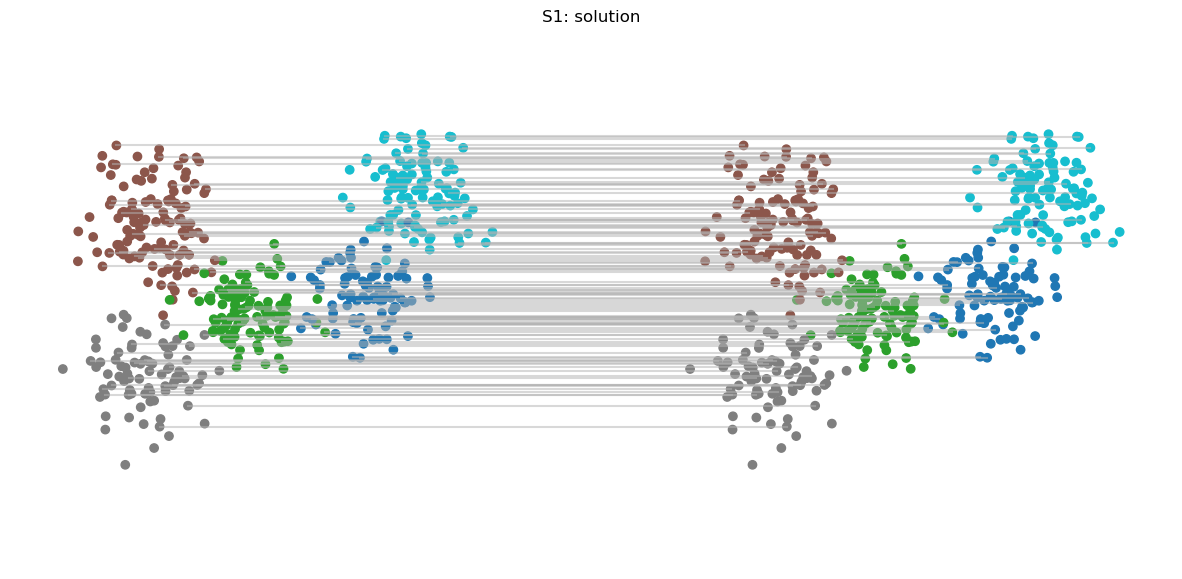

S1 finished. Label accuracy 1.000


### S2: Latent space with tiny noise, adjacency only

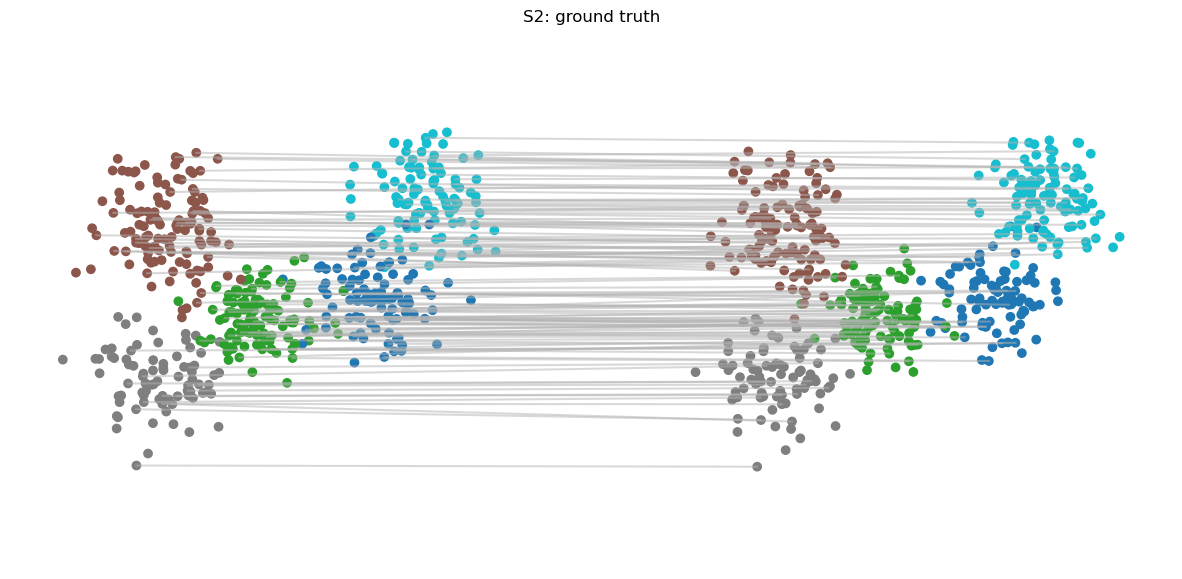

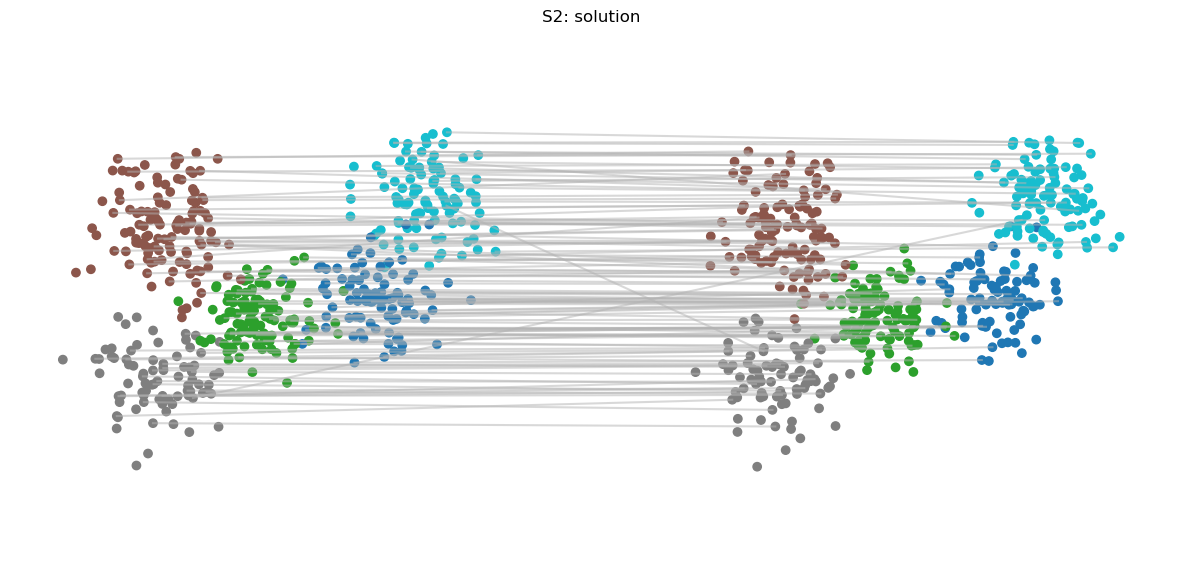

S2 finished. Label accuracy 0.922


### S3: Latent space with more noise, adjacency only

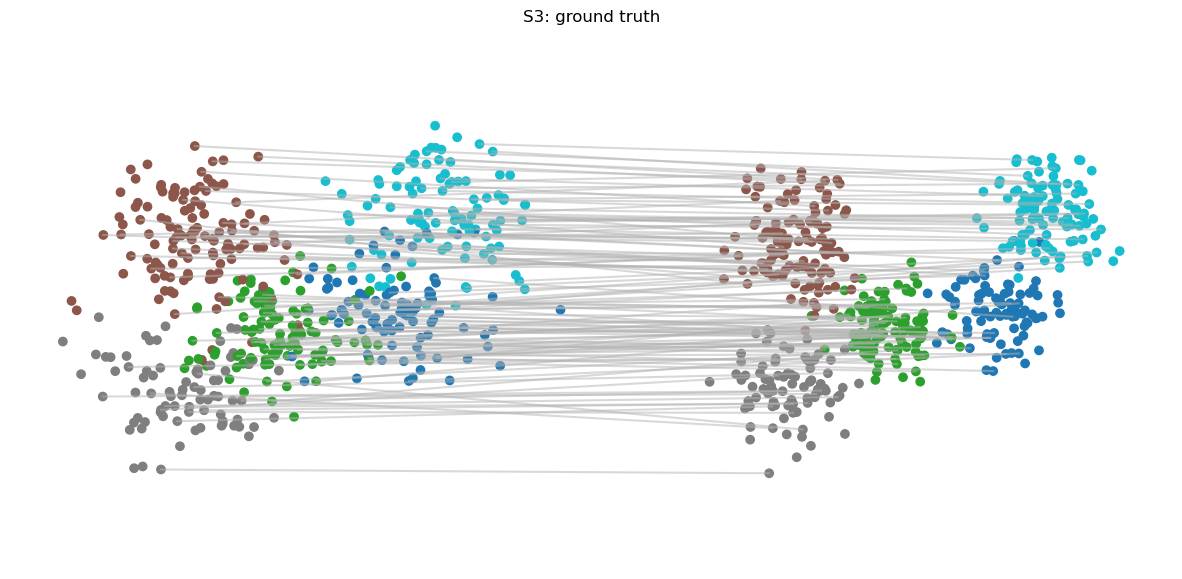

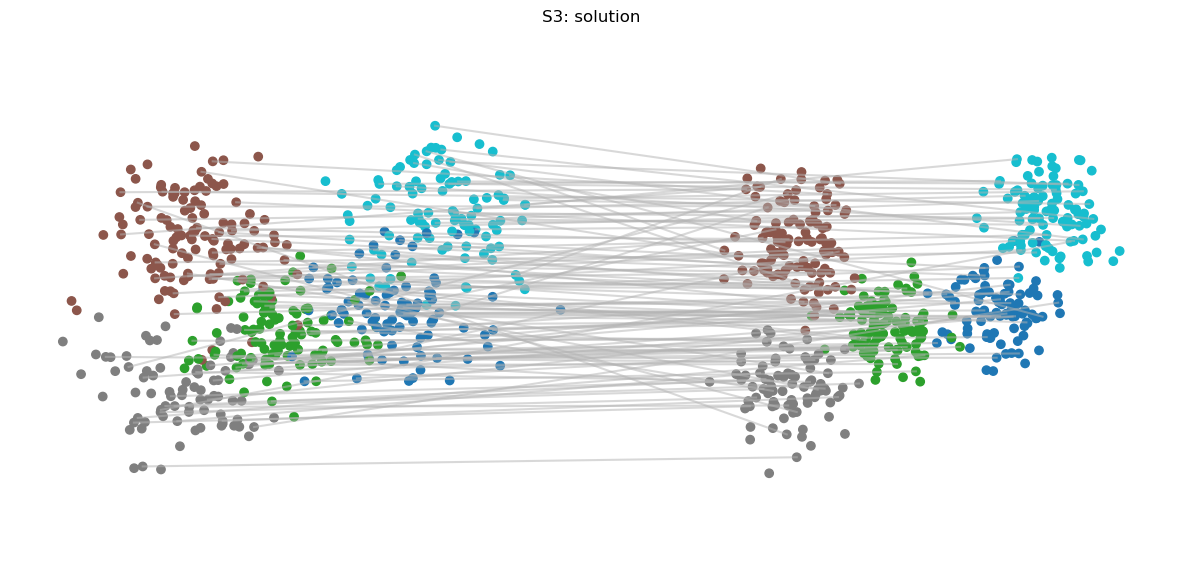

S3 finished. Label accuracy 0.474


### S4: Same noise as 3 with more neighbours

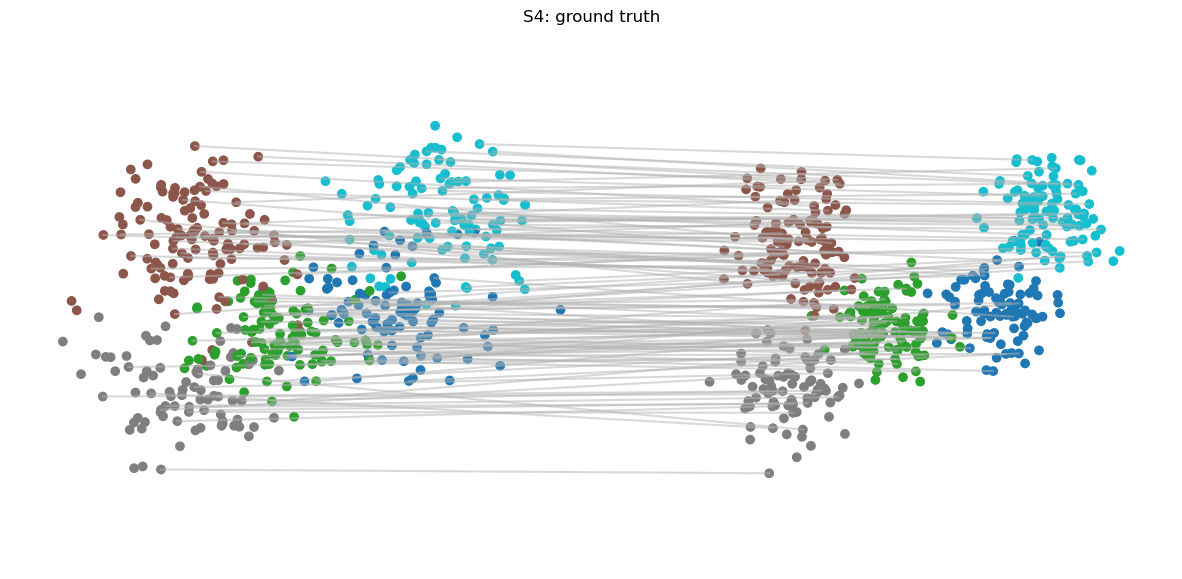

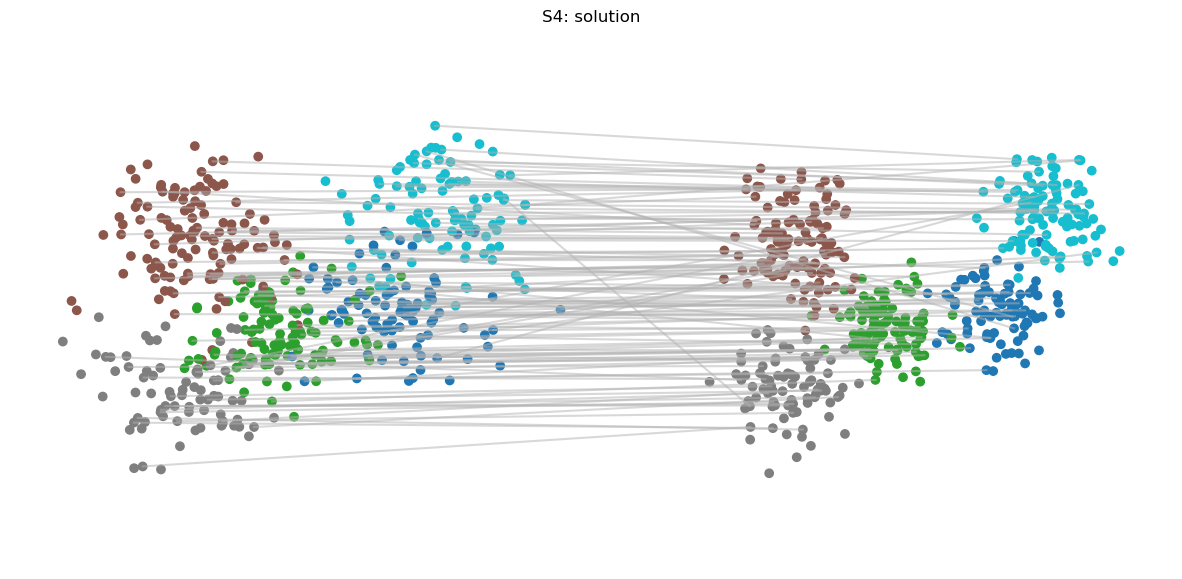

S4 finished. Label accuracy 0.732


### S5: Latent adjacency helped by noiseless RNA and ATAC

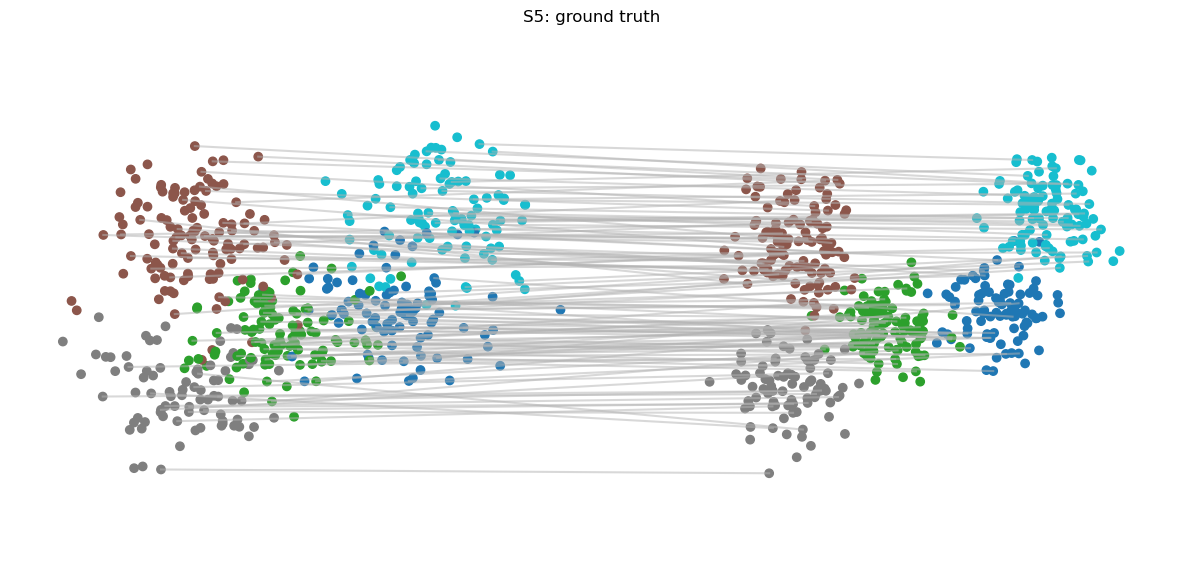

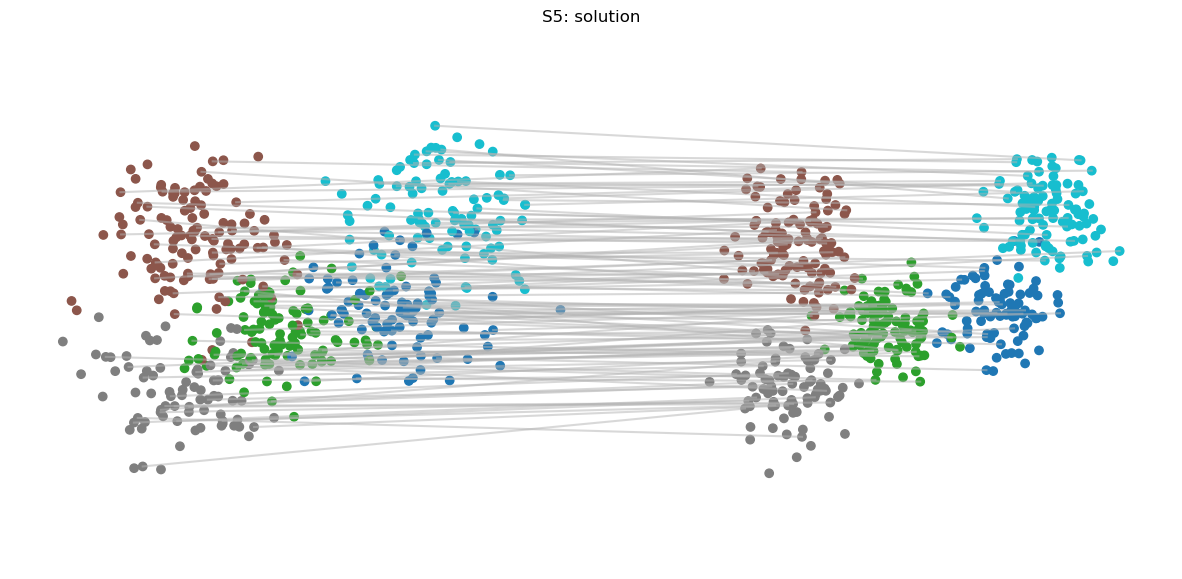

S5 finished. Label accuracy 0.858


### S6: Latent adjacency helped by noisy RNA and ATAC

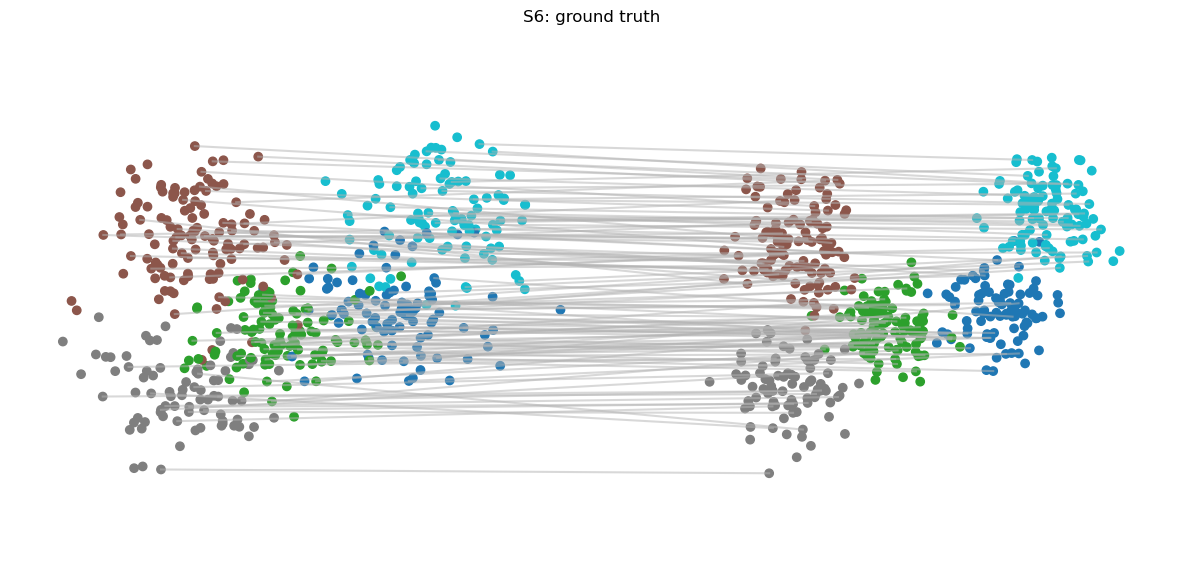

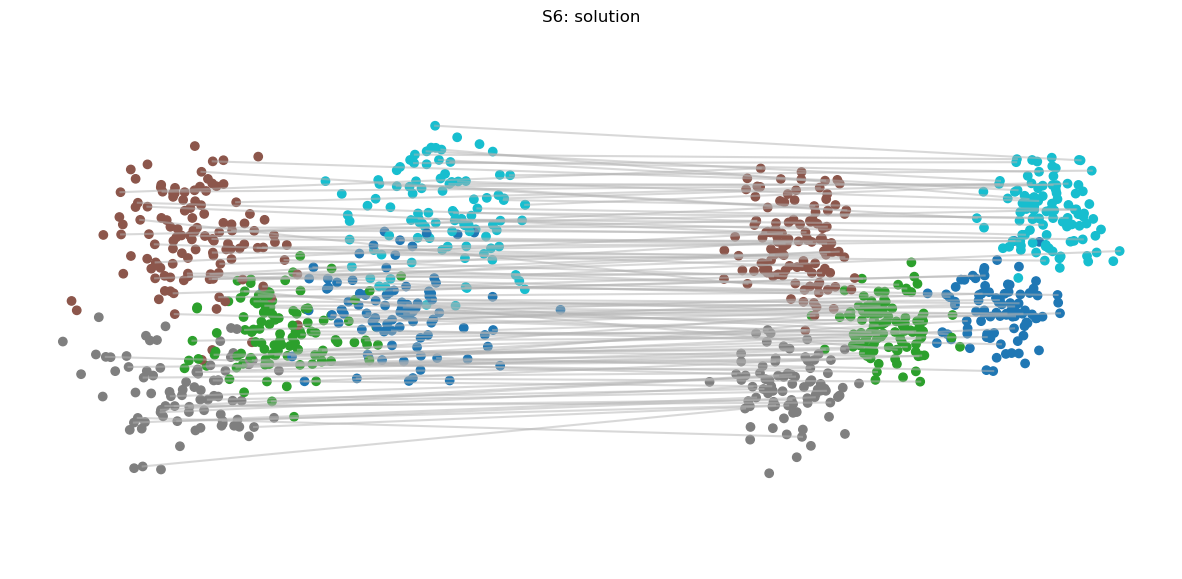

S6 finished. Label accuracy 0.838


### S7: Graphs from noisy RNA and ATAC, latent space not accessible

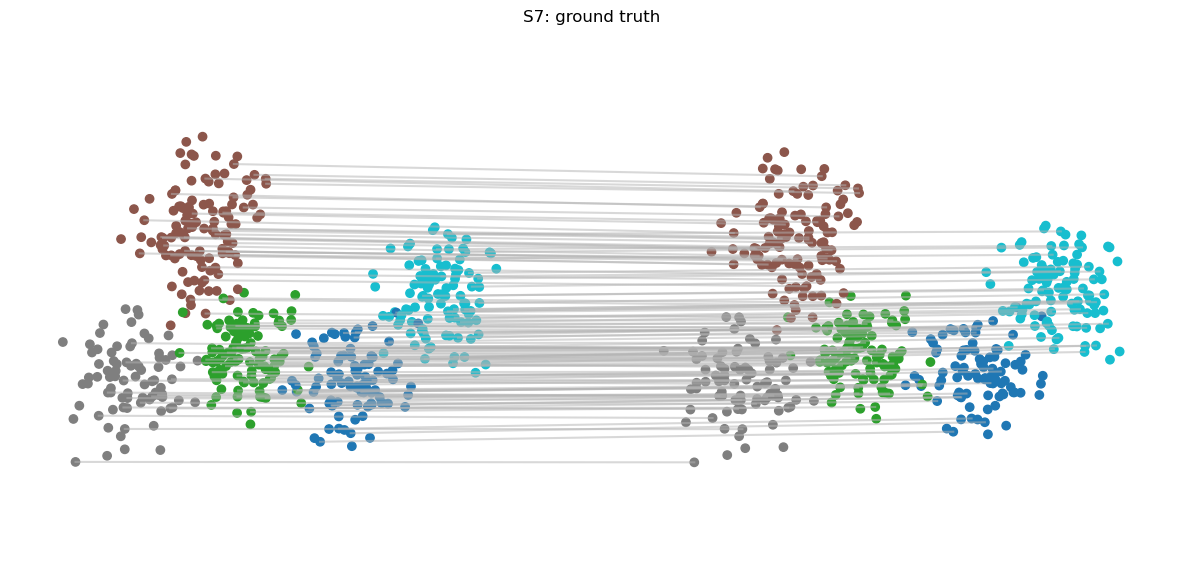

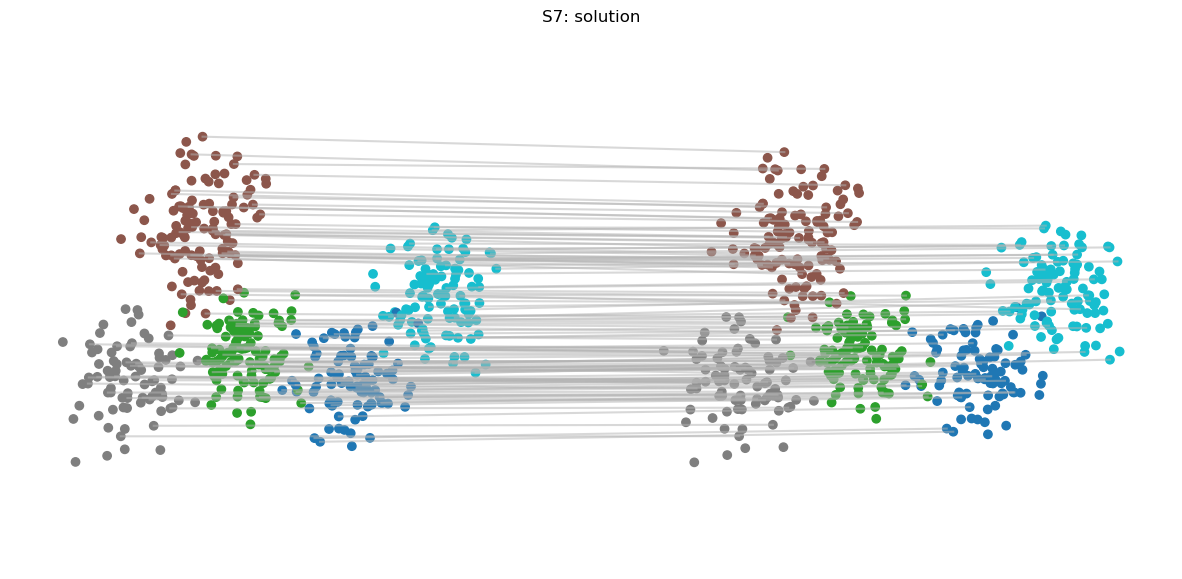

S7 finished. Label accuracy 0.988


### S8: As 7, RNA generated with a different D (5% of rows zeroed)

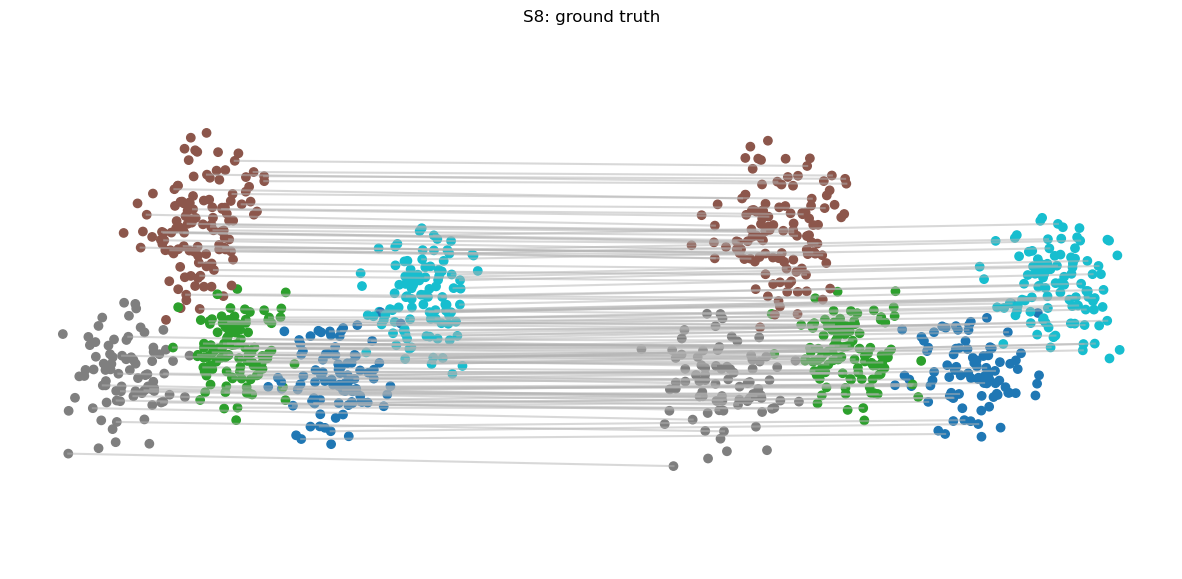

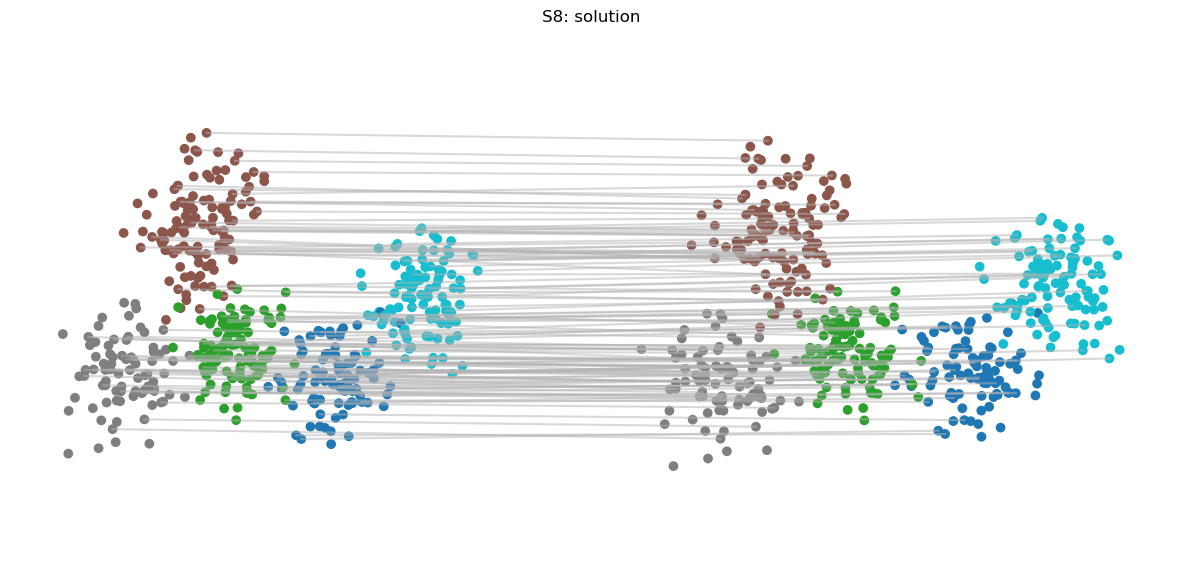

S8 finished. Label accuracy 0.960


### S9: As 8, with 70% of rows zeroed

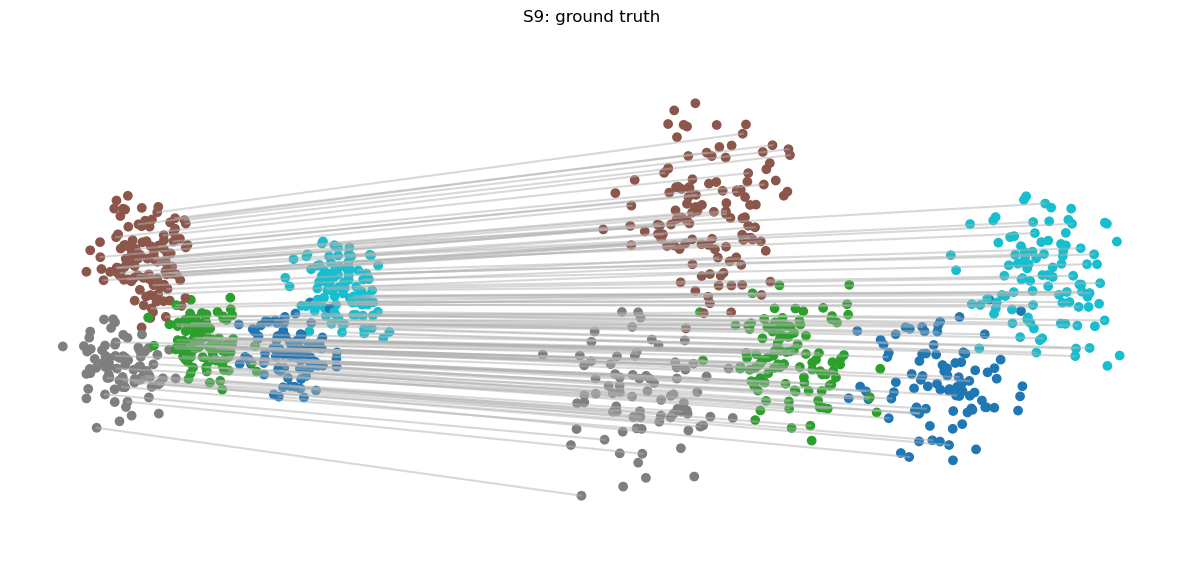

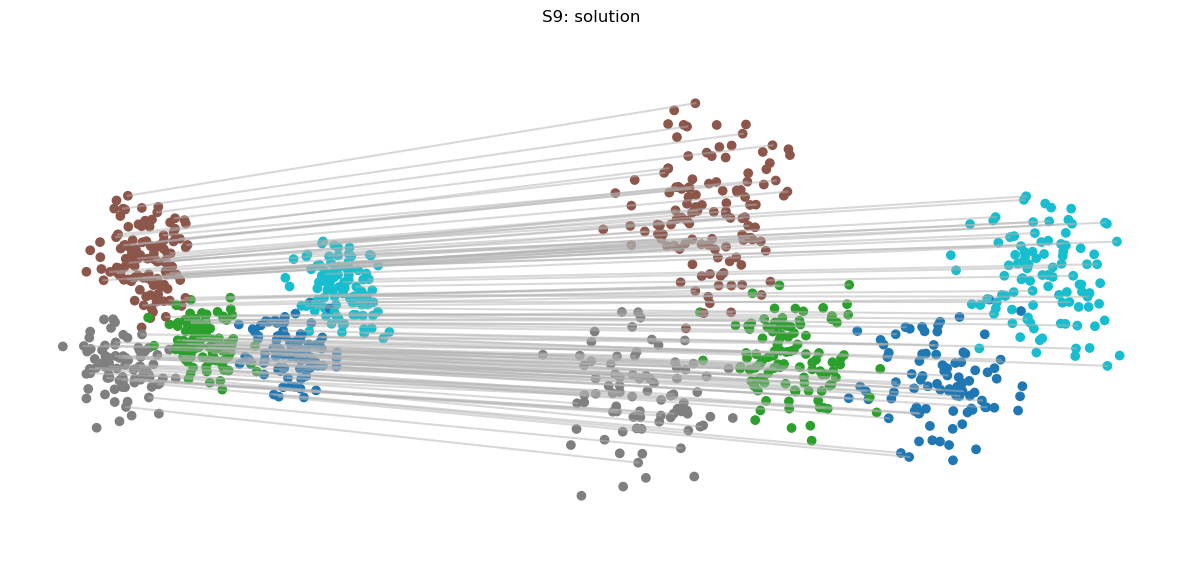

S9 finished. Label accuracy 0.988


### S10: As 8', with stronger regularization (c3=2000)

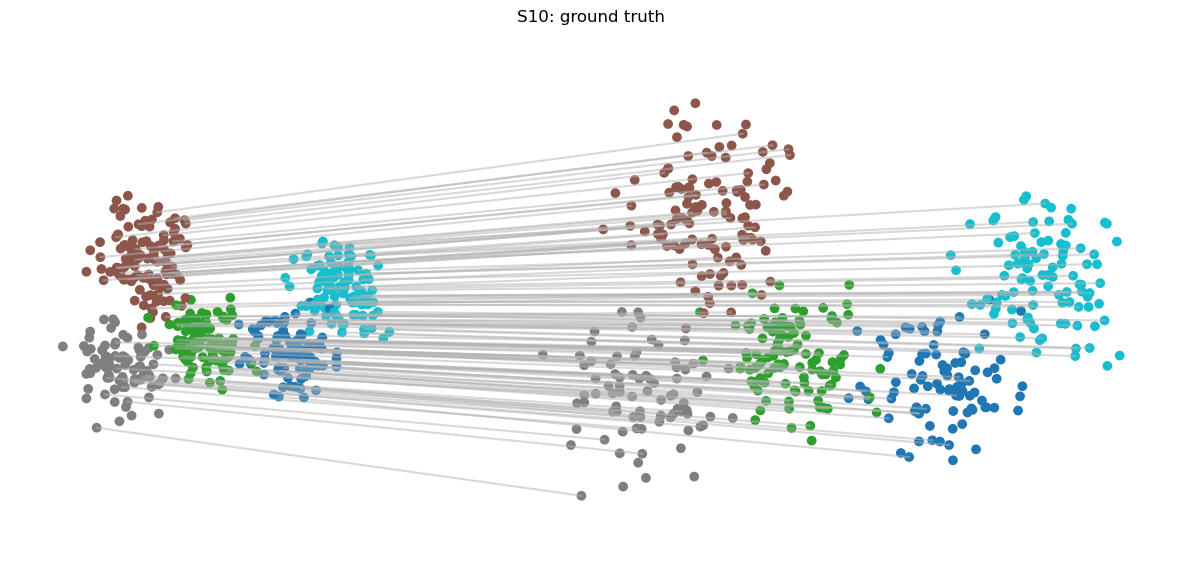

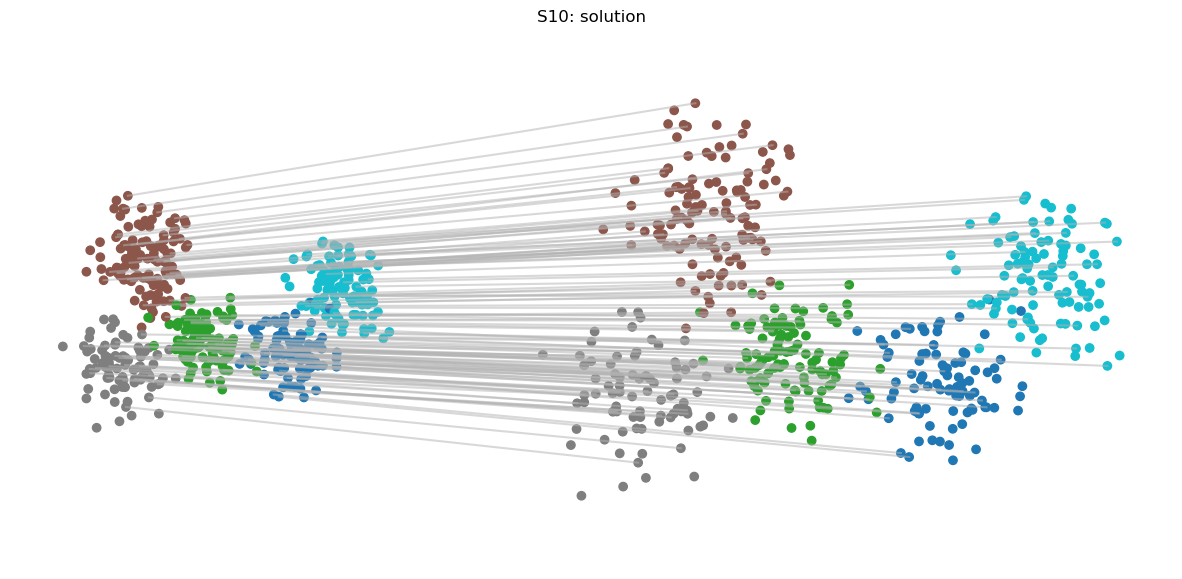

S10 finished. Label accuracy 0.992


### S11: As 9, with RNA and ATAC converted to Poisson counts

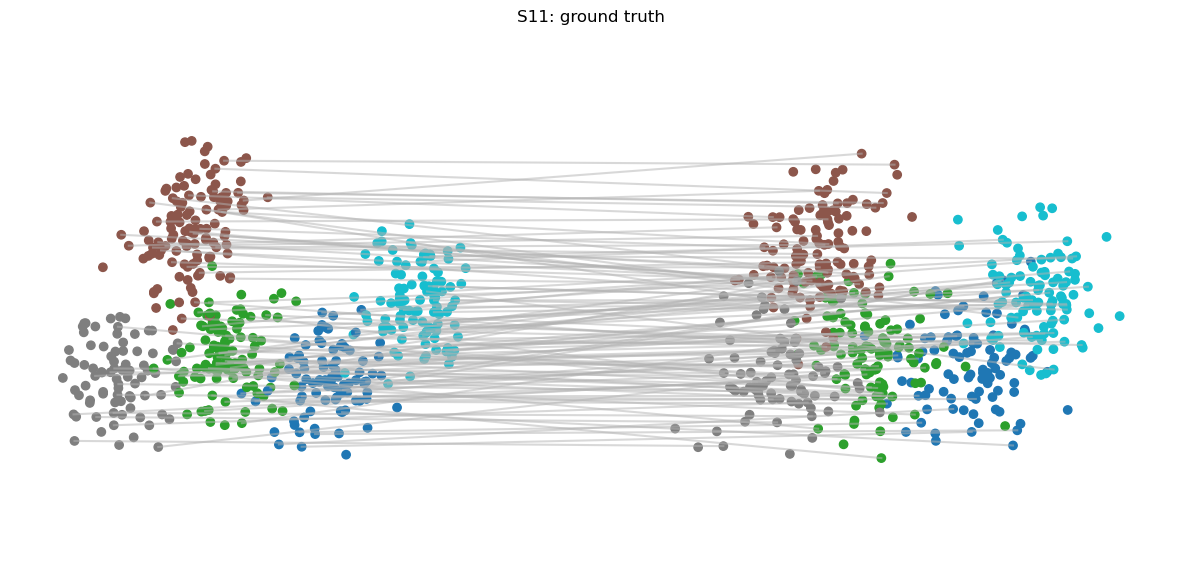

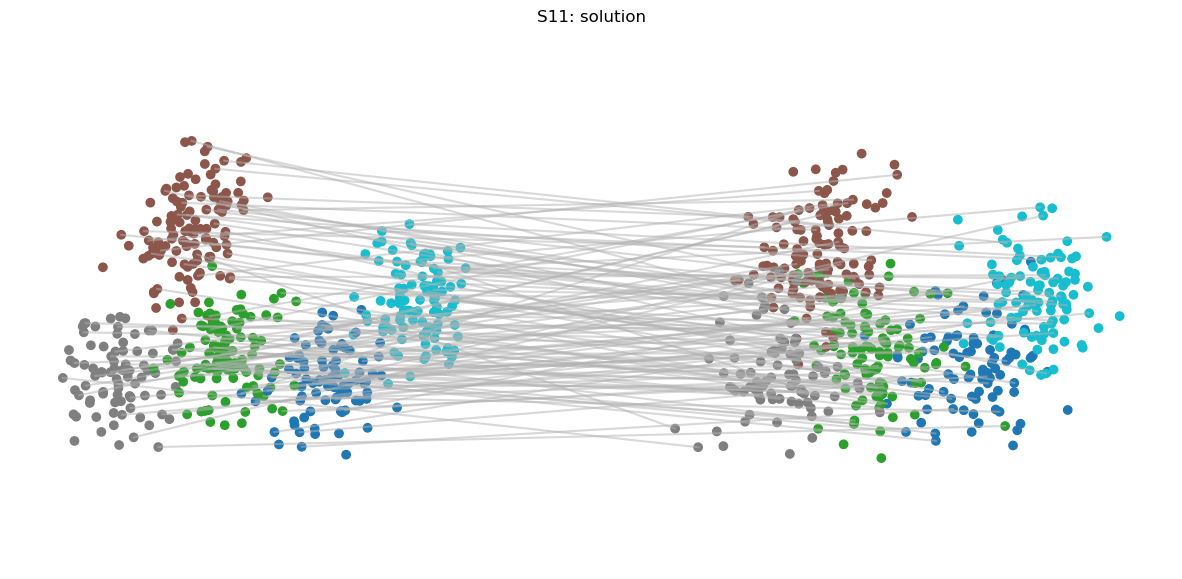

S11 finished. Label accuracy 0.430


In [3]:
table = []
for label in SIMS:
    cfg = configs.SIMULATIONS[configs.PAPER_SIMULATIONS[label]]
    display(Markdown(f"### {label}: {cfg['description']}"))
    start = time.time()

    rng1, rng2 = run.make_generators()
    Y, labels = data.make_latent_space(rng1, configs.MEANS, run.make_covariances(), configs.NCELLS)
    sim = run.simulate(cfg, rng1, rng2, Y, labels)
    _, P, w = graph_matching_withD(sim["D"], sim["Xa"], sim["Xb"], sim["A"], sim["B"], **cfg["solver"])
    s = calc_stats(sim["Ya"], sim["Yb"], sim["labels_a"], sim["labels_b"], sim["P0"], P, k=20)

    pa, pb = (sim["pca_a"], sim["pca_b"]) if sim["pca_a"] is not None else (sim["Ya"], sim["Yb"])
    plot_rng = np.random.default_rng(configs.SEED)
    plot_matching(plot_rng, pa[:, :2], pb[:, :2], sim["P0"], sim["labels_a"], sim["labels_b"],
                  show_fraction=0.25, title=f"{label}: ground truth")
    plot_matching(plot_rng, pa[:, :2], pb[:, :2], P, sim["labels_a"], sim["labels_b"],
                  show_fraction=0.25, title=f"{label}: solution")
    plt.show()

    table.append(f"| {label} | {s['label_accuracy']:.3f} | {s['relaxed_match_accuracy']:.3f} "
                 f"| {s['avg_dist_solution']:.3f} | {s['fract_exact_matches']:.3f} "
                 f"| {w.min():.3f} to {w.max():.3f} | {time.time() - start:.0f} s |")
    print(f"{label} finished. Label accuracy {s['label_accuracy']:.3f}")


## 3. Compare them

These values are from one run, so they will differ from the means of 10 repeats in `evaluation_demo.ipynb`. They match the first saved repeat in `results/runs/`, apart from small differences that can come from the number of threads.


In [4]:
display(Markdown("| Simulation | Acc | RMS | LDE | Exact matches | w | Time |\n|---|---|---|---|---|---|---|\n"
                 + "\n".join(table)))


| Simulation | Acc | RMS | LDE | Exact matches | w | Time |
|---|---|---|---|---|---|---|
| S1 | 1.000 | 1.000 | 0.000 | 0.996 | 1.000 to 1.000 | 6 s |
| S2 | 0.922 | 0.898 | 0.425 | 0.182 | 1.000 to 1.000 | 44 s |
| S3 | 0.474 | 0.194 | 3.650 | 0.016 | 1.000 to 1.000 | 80 s |
| S4 | 0.732 | 0.372 | 1.327 | 0.032 | 1.000 to 1.000 | 66 s |
| S5 | 0.858 | 0.828 | 1.112 | 0.254 | 0.874 to 1.321 | 101 s |
| S6 | 0.838 | 0.794 | 1.072 | 0.184 | 0.877 to 1.309 | 104 s |
| S7 | 0.988 | 1.000 | 1.213 | 0.634 | 0.919 to 1.238 | 111 s |
| S8 | 0.960 | 0.996 | 1.235 | 0.390 | 0.021 to 2.495 | 108 s |
| S9 | 0.988 | 1.000 | 1.222 | 0.594 | 0.042 to 2.139 | 98 s |
| S10 | 0.992 | 1.000 | 1.211 | 0.664 | 0.010 to 0.218 | 836 s |
| S11 | 0.430 | 0.098 | 3.395 | 0.004 | -0.151 to 5.486 | 4946 s |